# RMTB vs. Kriging: does RMTB's uncertainty actually scale better?

RMTB's posterior query cost is expected to be set by its basis
resolution (`num_ctrl_pts`), not by the number of training points,
while Kriging's cost grows with both. The five tests below evaluate
this claim.

This notebook does not fit or time anything itself. Each test is a
standalone script in `smoothing_splines_uq/benchmarks/`, writing its
results to `smoothing_splines_uq/benchmarks/results/` as CSV; this
notebook only loads and plots those files (Section 1.3).

## 1. Theoretical background

### 1.1 The claim, precisely

RMTB's posterior mean and variance are both linear in a fixed-size
B-spline basis: $\mathrm{Var}_{\mathrm{bayes}}(x^*)=\sigma^2
f(x^*)^\top\mathrm{mtx}^{-1}f(x^*)$ (Notebook 4), where `mtx` is
`num_ctrl_pts`-sized and does not grow with $n$. Kriging (`SMT KRG`)
and `PolyharmonicSmoothingSpline` are kernel methods: prediction
correlates each query point against (in the worst case) every training
point, an $O(n)$-or-worse cost per query.

### 1.2 Models compared

- **RMTBUQ** (weight route unless stated otherwise) -- the subject of
  this benchmark.
- **SMT KRG** (Matern-3/2, linear trend).
- **PolyharmonicSmoothingSpline** -- a kernel method with its own
  closed-form variance (Notebook 1/2).
- **NdGridCubicSmoothingSplineUQ** -- grid datasets only, at
  `off_grid_method="exact"` (Test 5 measures `"fast"` separately).

Fit time is reported as context throughout, and is the explicit
subject of Test 1.

### 1.3 Methodology

Each test is a standalone script runnable
individually or in sequence via `run_all.py`. Each script pins
BLAS/OpenMP to a single thread and runs as its own subprocess,
sequentially.

Dataset sizes: `KRG`'s MLE fit becomes impractically slow around
$n\approx900$ on the benchmarking machine. Three size tiers
(`small`/`medium`/`big`) are used per kind (grid, scattered); grid
sizes are the nearest perfect squares to the target $n$ (`256`, `625`
rather than `250`, `600`).

Mean and variance predictions are separable calls for all four models
(`predict_values()`/`predict_variances()`, `.mean()`/`.variance()`,
`predict_mean()`/`.variance()`). Test 2 calculates time for the mean call; Test 3
calculates time for the variance call (`test2_mean_predict_time.py`,
`test3_variance_predict_time.py`). Both scripts fit every model on
every dataset first, then time predictions in an order shuffled
independently of $n$, to prevent timing-order effects from correlating
with dataset size.

Prediction time is the minimum of several repeated calls; fit time is
a single timed call per model per dataset, so fit-time figures carry
more run-to-run noise than prediction-time figures. Absolute
wall-clock values are not expected to reproduce exactly between runs;
relative comparisons (model vs. model, size vs. size) are the robust
signal.

## 2. Setup: loading the pre-computed benchmark results

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

# Fixed per-model colors and bar order, used consistently across all
# histogram figures below (Tests 1-3): warm brown for KRG, purple for
# the polyharmonic reference, green for the grid-exact csaps class,
# blue for RMTBUQ.
MODEL_ORDER = ["KRG", "PolyharmonicSmoothingSpline", "NdGridCubicSmoothingSplineUQ", "RMTBUQ"]
MODEL_COLORS = {
    "KRG": "#BE7F3D",
    "PolyharmonicSmoothingSpline": "#9A72C9",
    "NdGridCubicSmoothingSplineUQ": "#4FAE78",
    "RMTBUQ": "#4F8FD1",
}


def set_log_y_ticks(ax):
    """Plain (non-scientific) numeric labels on the log-scale y-axis --
    major ticks at each decade, minor ticks at 2x/5x each decade -- shown
    on every panel regardless of sharey."""
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.yaxis.get_major_formatter().set_scientific(False)
    ax.yaxis.set_minor_locator(mticker.LogLocator(subs=(2, 5)))
    ax.yaxis.set_minor_formatter(mticker.ScalarFormatter())
    ax.yaxis.get_minor_formatter().set_scientific(False)
    ax.tick_params(axis="y", which="both", labelleft=True, labelsize=8)


RESULTS_DIR = Path("..") / "benchmarks" / "results"

# Long-format fit-time results, one row per (dataset, model) -- Test 1.
fit_long = pd.read_csv(RESULTS_DIR / "test1_fit_time.csv")

# Long-format mean/variance predict-time results, one row per (dataset,
# model) each -- Test 2 (mean) and Test 3 (variance) respectively.
mean_long = pd.read_csv(RESULTS_DIR / "test2_mean_predict_time.csv")
var_long = pd.read_csv(RESULTS_DIR / "test3_variance_predict_time.csv")

# Already-small, purpose-built tables for Tests 4-5.
dual_df = pd.read_csv(RESULTS_DIR / "test4_weight_vs_dual.csv").set_index("dataset")
dual_diag_df = pd.read_csv(RESULTS_DIR / "test4_dual_diagnostic.csv").set_index("dataset")
naive_df = pd.read_csv(RESULTS_DIR / "test5_batched_vs_naive.csv").set_index("dataset")
csaps_speed_df = pd.read_csv(RESULTS_DIR / "test5_csaps_exact_vs_fast.csv").set_index("dataset")

dataset_order = [
    "small grid (n=64)", "medium grid (n=256)", "big grid (n=625)",
    "small scattered (n=30)", "medium scattered (n=250)", "big scattered (n=600)",
]

fit_long[["dataset", "kind", "n"]].drop_duplicates().set_index("dataset").loc[dataset_order]

,kind,n
dataset,,
small grid (n=64),grid,64
medium grid (n=256),grid,256
big grid (n=625),grid,625
small scattered (n=30),scattered,30
medium scattered (n=250),scattered,250
big scattered (n=600),scattered,600


## Test 1 -- fit time vs. `n`

`KRG`'s MLE search is expected to scale poorly with $n$. `RMTBUQ`'s
fit cost is expected to depend on `num_ctrl_pts` (fixed at 20), not
$n$.

In [2]:
# Produced by smoothing_splines_uq/benchmarks/test1_fit_time.py
fit_df = fit_long.pivot(index="model", columns="dataset", values="fit_time_ms")
fit_df = fit_df.reindex(MODEL_ORDER)[dataset_order]
fit_df

dataset,small grid (n=64),medium grid (n=256),big grid (n=625),small scattered (n=30),medium scattered (n=250),big scattered (n=600)
model,,,,,,
KRG,2.1713e+02,2.3139e+03,2.4879e+04,5.8400e+02,2.0816e+03,1.9629e+04
PolyharmonicSmoothingSpline,4.8755e+01,3.7973e+02,2.9783e+02,1.2214e+00,5.3620e+02,3.0844e+02
NdGridCubicSmoothingSplineUQ,8.3163e+00,8.3136e+00,1.5875e+01,NaN,NaN,NaN
RMTBUQ,1.3990e+02,1.7428e+02,6.0035e+02,3.7771e+01,1.2890e+02,4.0268e+02


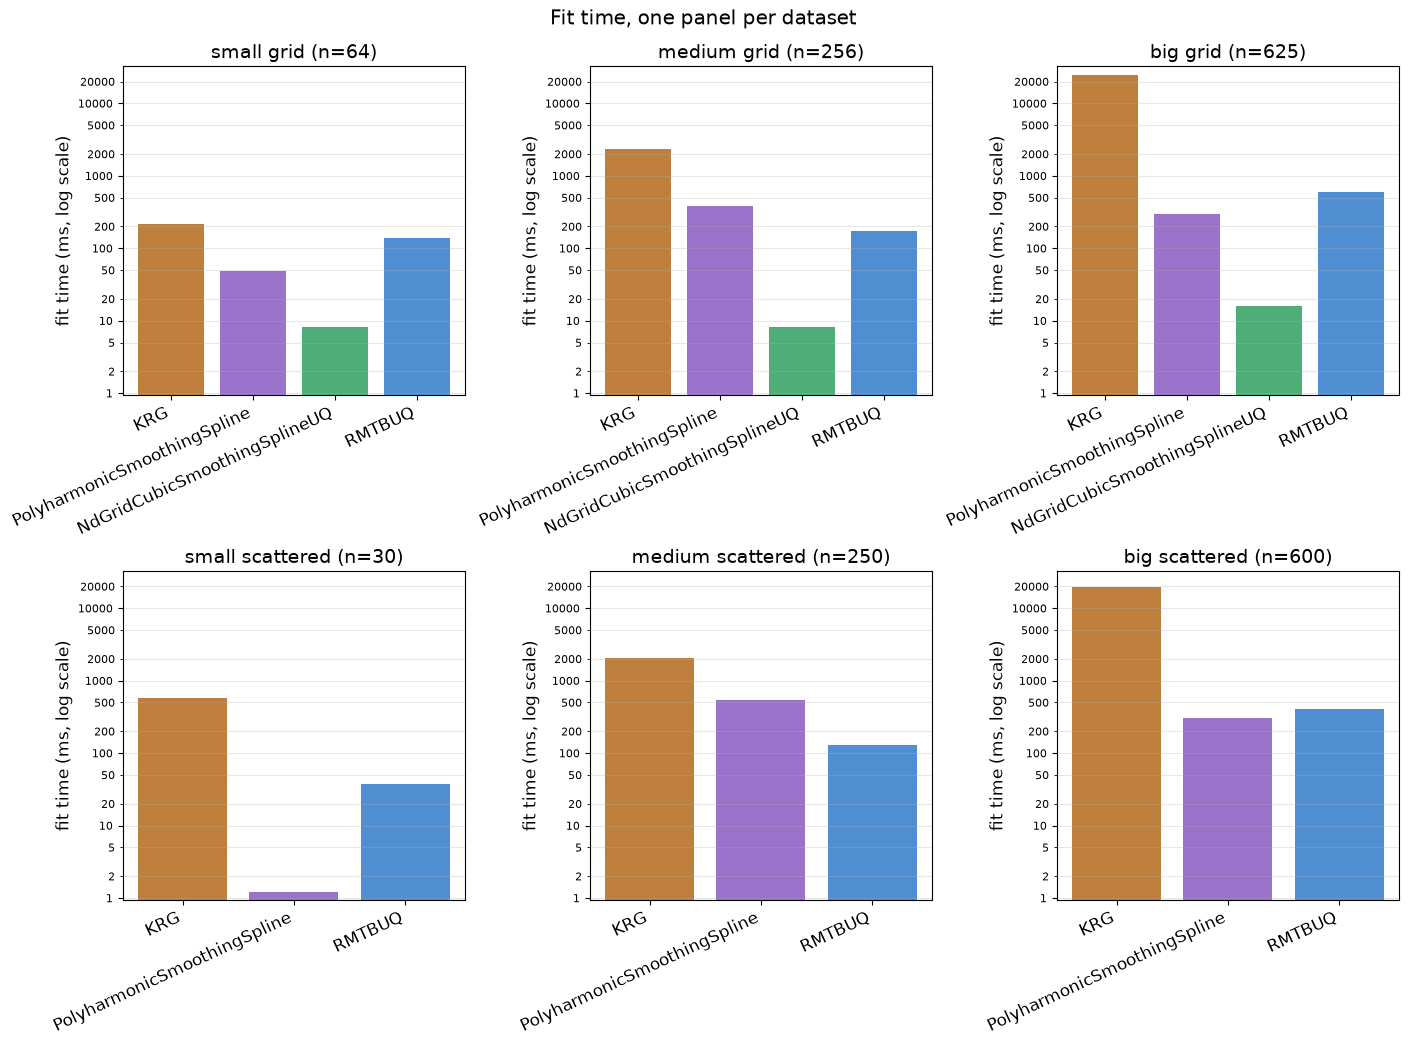

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(14, 10), constrained_layout=True, sharey=True)
ymin, ymax = fit_df.min().min(), fit_df.max().max()

for ax, name in zip(axs.flat, dataset_order):
    present = fit_df[name].dropna()
    colors = [MODEL_COLORS[m] for m in present.index]
    ax.bar(present.index, present.to_numpy(), color=colors)
    ax.set_yscale("log")
    ax.set_ylim(ymin / 1.3, ymax * 1.3)
    set_log_y_ticks(ax)
    ax.set_ylabel("fit time (ms, log scale)")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=25)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    ax.grid(alpha=0.3, which="both", axis="y")

fig.suptitle("Fit time, one panel per dataset", y=1.03)
plt.show()

**Confirmed.** 
- `KRG`'s fit time increases by roughly two orders of magnitude from the smallest to the largest grid dataset, and by more than 30x on scattered data. 
- `RMTBUQ`'s fit time grows by roughly 4x on grid data and 11x on scattered data over the same range, staying well below `KRG`'s own growth.
- `NdGridCubicSmoothingSplineUQ` grows by less than 2x across grid sizes and remains more than an order of magnitude below `RMTBUQ`.
- `PolyharmonicSmoothingSpline` varies by roughly 8x on grid data but by more than two orders of magnitude on scattered data, driven by an unusually small value at the smallest size. 

At the largest grid size, `KRG`'s fit time exceeds `RMTBUQ`'s by more than 40x.

## Test 2 -- mean (surface value) prediction time vs. `n`

Each model's mean-only call (`test2_mean_predict_time.py`), same 2000
shared query points for every dataset.

In [4]:
# Produced by smoothing_splines_uq/benchmarks/test2_mean_predict_time.py
mean_df = mean_long.pivot(index="model", columns="dataset", values="predict_time_ms")
mean_df = mean_df.reindex(MODEL_ORDER)[dataset_order]
mean_df

dataset,small grid (n=64),medium grid (n=256),big grid (n=625),small scattered (n=30),medium scattered (n=250),big scattered (n=600)
model,,,,,,
KRG,1.2691e+01,4.9097e+01,1.1650e+02,4.0732e+00,4.7101e+01,1.1370e+02
PolyharmonicSmoothingSpline,5.5138e+00,2.9023e+01,7.4093e+01,3.4605e+00,2.6363e+01,7.7028e+01
NdGridCubicSmoothingSplineUQ,2.0778e+01,2.1211e+01,2.2314e+01,NaN,NaN,NaN
RMTBUQ,1.1188e+00,1.2423e+00,1.2991e+00,1.3054e+00,1.7114e+00,1.6377e+00


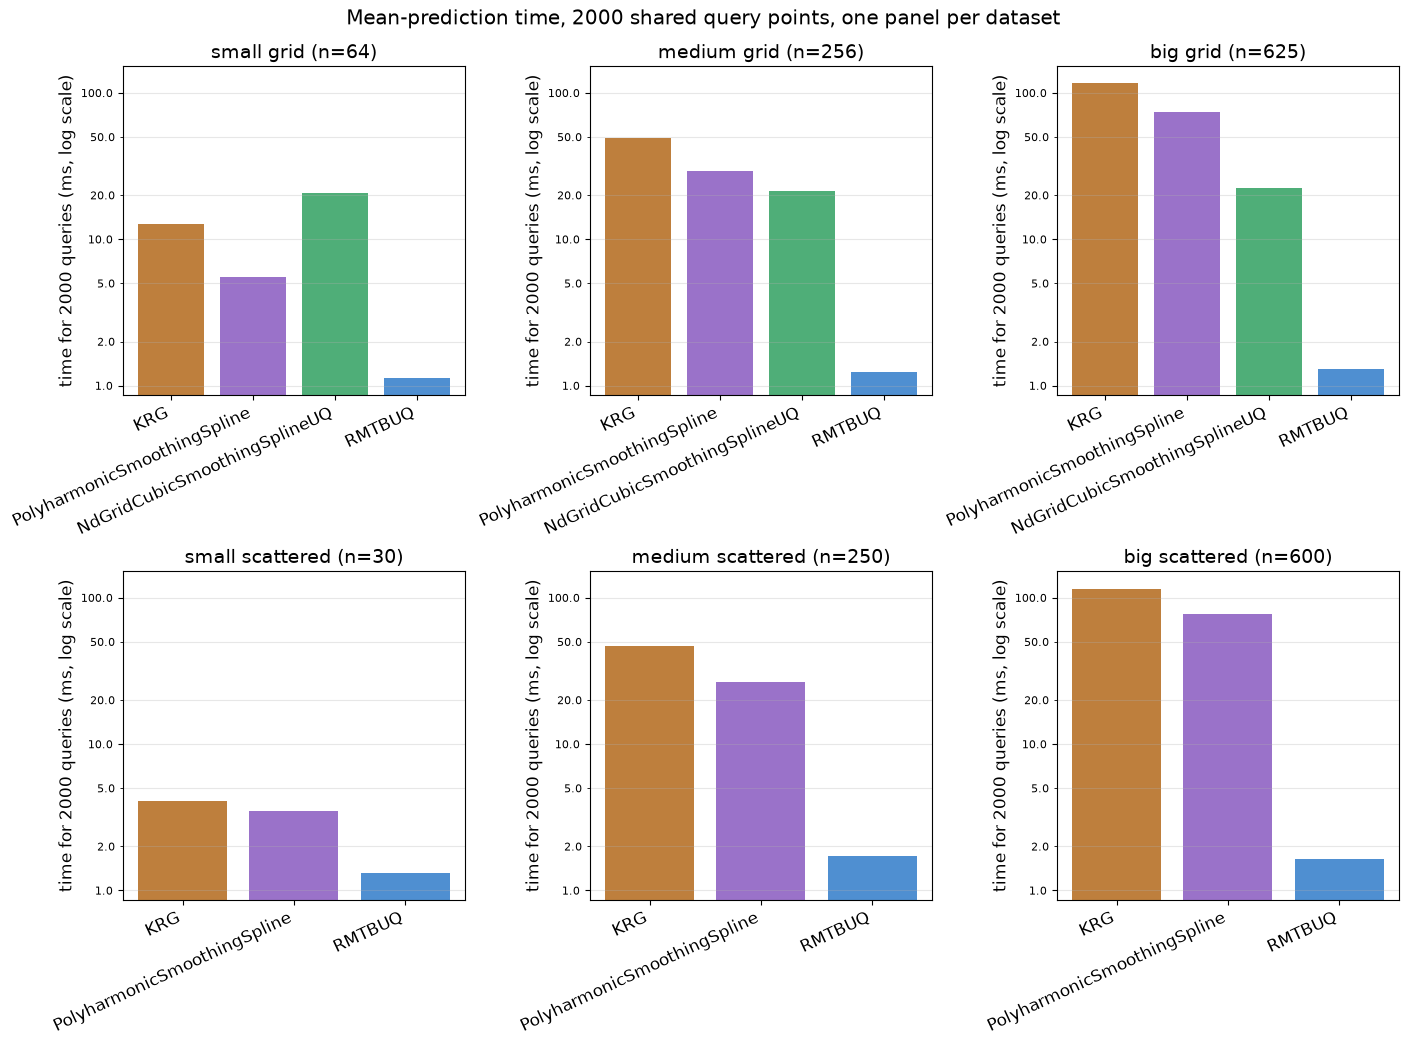

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 10), constrained_layout=True, sharey=True)
ymin, ymax = mean_df.min().min(), mean_df.max().max()

for ax, name in zip(axs.flat, dataset_order):
    present = mean_df[name].dropna()
    colors = [MODEL_COLORS[m] for m in present.index]
    ax.bar(present.index, present.to_numpy(), color=colors)
    ax.set_yscale("log")
    ax.set_ylim(ymin / 1.3, ymax * 1.3)
    set_log_y_ticks(ax)
    ax.set_ylabel("time for 2000 queries (ms, log scale)")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=25)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    ax.grid(alpha=0.3, which="both", axis="y")

fig.suptitle("Mean-prediction time, 2000 shared query points, one panel per dataset", y=1.03)
plt.show()

**Confirmed.** 
- `RMTBUQ`'s mean-only predict time varies by less than 55% across all six datasets, and is the cheapest call in this benchmark by roughly an order of magnitude. 
- `NdGridCubicSmoothingSplineUQ`'s mean call is similarly flat (within ~7%), but costs roughly 17x more than `RMTBUQ`'s at the largest grid size. 
- `KRG`'s mean time grows by roughly 9x on grid data and 28x on scattered data; 
- `PolyharmonicSmoothingSpline` grows by roughly 13x and 22x respectively.

**Implementation note.** `NdGridCubicSmoothingSplineUQ`'s elevated but
flat premium over `RMTBUQ` is an implementation bottleneck, not a
property of the tensor-product construction. `csaps`'s underlying
evaluator accepts only grid-tuple queries; the default
`off_grid_method="exact"` recovers values at scattered points by
evaluating the full Cartesian product of the query set's per-axis
unique coordinates and discarding all but the requested entries. For
$N_{\mathrm{query}}=2000$ points with no repeated coordinates, this
evaluates a $2000\times2000$ grid to recover $2000$ values -- a
$2000\times$ excess in raw evaluation count, independent of $n$,
consistent with the flat (not growing) premium observed above.
`off_grid_method="fast"` avoids this entirely by evaluating a
pre-built `RectBivariateSpline` directly at the query points (Test 5,
$\sim$54x-60x faster).

## Test 3 -- variance prediction time vs. `n`

Each model's variance-only call (`test3_variance_predict_time.py`),
same query points as Test 2.

In [6]:
# Produced by smoothing_splines_uq/benchmarks/test3_variance_predict_time.py
var_df = var_long.pivot(index="model", columns="dataset", values="predict_time_ms")
var_df = var_df.reindex(MODEL_ORDER)[dataset_order]
var_df

dataset,small grid (n=64),medium grid (n=256),big grid (n=625),small scattered (n=30),medium scattered (n=250),big scattered (n=600)
model,,,,,,
KRG,1.3738e+01,5.9688e+01,1.6447e+02,6.7495e+00,5.9941e+01,1.4988e+02
PolyharmonicSmoothingSpline,9.3357e+01,1.4773e+02,5.2092e+02,5.0186e+01,1.7908e+02,6.1366e+02
NdGridCubicSmoothingSplineUQ,1.7632e+01,1.9044e+01,2.2653e+01,NaN,NaN,NaN
RMTBUQ,1.2766e+01,1.7582e+01,1.2799e+01,1.2390e+01,1.2382e+01,1.2805e+01


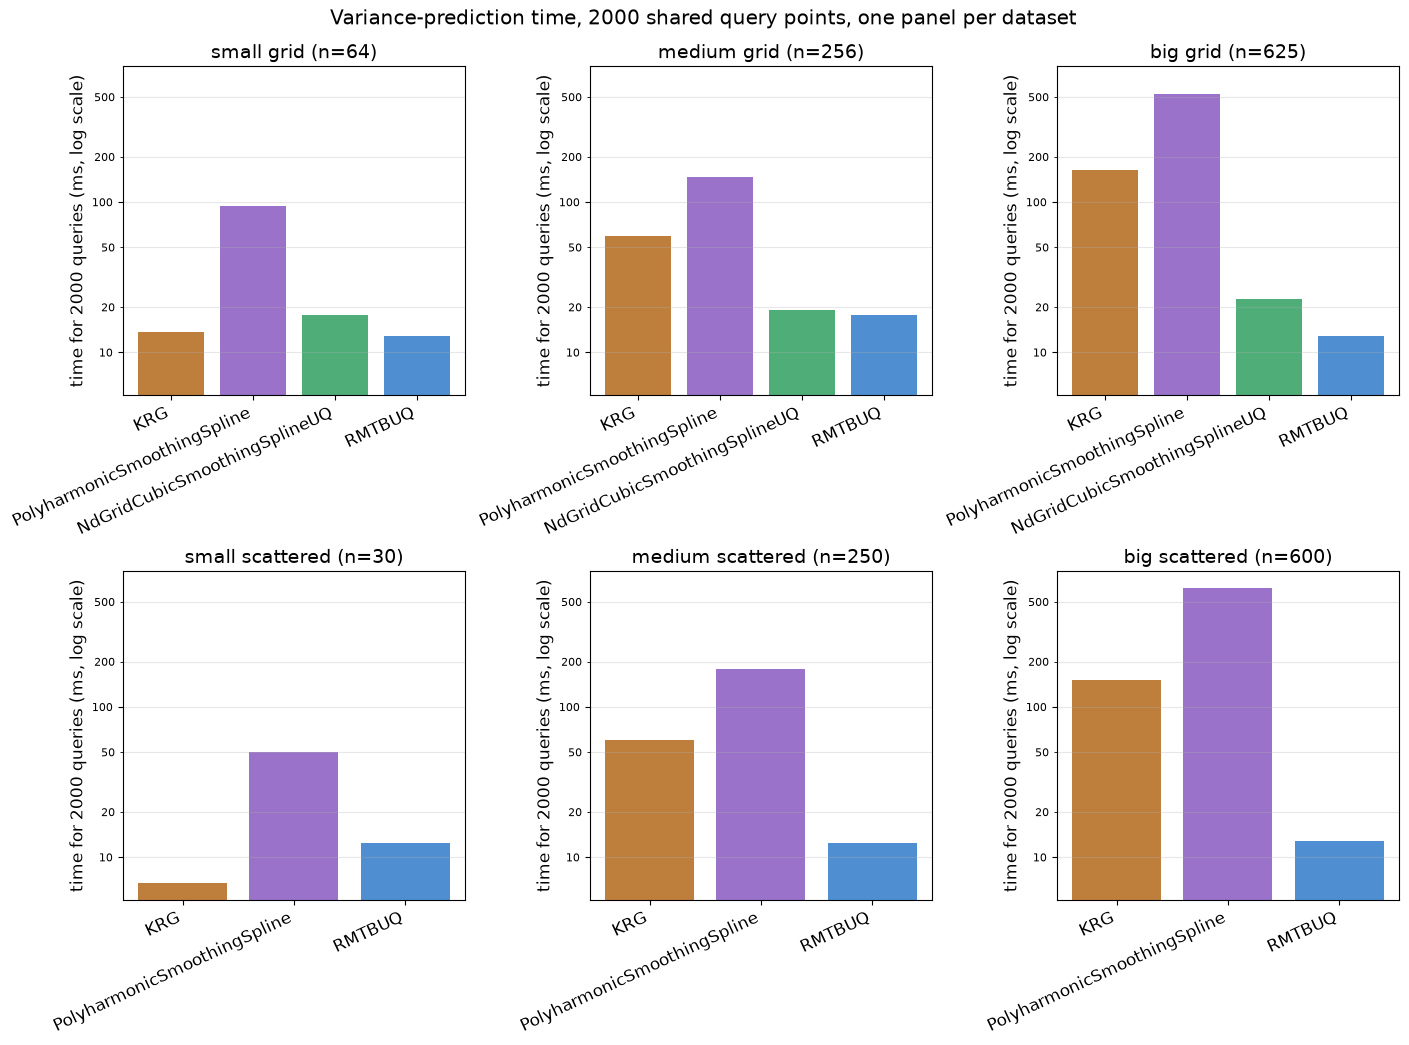

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(14, 10), constrained_layout=True, sharey=True)
ymin, ymax = var_df.min().min(), var_df.max().max()

for ax, name in zip(axs.flat, dataset_order):
    present = var_df[name].dropna()
    colors = [MODEL_COLORS[m] for m in present.index]
    ax.bar(present.index, present.to_numpy(), color=colors)
    ax.set_yscale("log")
    ax.set_ylim(ymin / 1.3, ymax * 1.3)
    set_log_y_ticks(ax)
    ax.set_ylabel("time for 2000 queries (ms, log scale)")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=25)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    ax.grid(alpha=0.3, which="both", axis="y")

fig.suptitle("Variance-prediction time, 2000 shared query points, one panel per dataset", y=1.03)
plt.show()

**Confirmed.** 
- `RMTBUQ`'s variance-only predict time stays mainly flat (varies by at most ~40%) across all six datasets.
- `NdGridCubicSmoothingSplineUQ`'s variance call exhibit low dependancy on the size of the query datasets (varies by about 28%) and stays within the same order of magnitude as `RMTBUQ`'s throughout. 
- `KRG`'s variance time grows by roughly 12x on grid data and 22x on scattered data.
- `PolyharmonicSmoothingSpline` grows by roughly 6x on grid data and 12x on scattered data, and is the most expensive of the four models at the largest sizes -- more than 3x `KRG`'s own variance time at the largest grid size.

## Test 4 -- `RMTBUQ` weight route vs. dual route prediction speed

Both routes compute the same posterior (Notebook 5). Compared on the
two scattered datasets, using the regularization boost validated in
Notebook 5.

In [8]:
# Produced by smoothing_splines_uq/benchmarks/test4_weight_vs_dual.py
dual_df

,n,cond_full_hess,safe_lt_1e8,weight_route_ms,dual_route_ms,ratio_dual_over_weight
dataset,,,,,,
small scattered (n=30),30,1.1939e+07,True,1.6883e+01,3.7024e+02,2.1929e+01
big scattered (n=600),600,1.1939e+07,True,2.3176e+01,5.7996e+02,2.5024e+01


### Why the dual route is slower than the formula alone suggests

`predict_variances_dual()` rebuilds and inverts an entire
regularization-boosted sibling model on every call, rather than
caching it as the weight route caches its own factorization.

In [9]:
# Produced by smoothing_splines_uq/benchmarks/test4_weight_vs_dual.py
# (dual_route_diagnostic: cumulative-checkpoint timing of a line-by-line
# replica, confirmed to match the shipped method's output exactly).
dual_diag_df

,n,refit_ms,refit_invert_cumulative_ms,total_ms,invert_share,refit_share,remaining_share,max_diff_vs_shipped
dataset,,,,,,,,
big scattered (n=600),600,1.4181e+02,4.8332e+02,7.3983e+02,4.6160e-01,1.9168e-01,3.4671e-01,0.0000e+00


**Confirmed.** Refitting the sibling model and inverting its Hessian
together account for roughly two-thirds of the dual route's total
call time in this run; the remainder is the per-query solve, which is
unavoidable. This breakdown varies substantially between runs, since
refitting is itself a single-timed-call operation, but neither step is
ever cached, unlike the weight route's own matrix factorization.

**Confirmed.** The dual route is roughly 22x-25x slower than the
weight route at both scattered sizes tested. The gap is not explained
by the formula's own $O(m^2)$ cost alone; it comes from rebuilding and
re-inverting an internal model on every call instead of caching it.
The dual route's practical value remains training-time conditioning
robustness (Notebook 5), not query speed.

## Test 5 -- do the engineering choices behind these classes pay off?

Part 1: `RMTBUQ.predict_variances()` factors `mtx` once and solves all
queries in one batched Cholesky call, checked against a naive
per-query loop.

In [10]:
# Produced by smoothing_splines_uq/benchmarks/test5_engineering_choices.py
# (the batched_vs_naive() part)
naive_df

,n,batched_ms,naive_loop_ms,speedup,max_diff
dataset,,,,,
big scattered (n=600),600,1.6958e+01,5.5793e+02,3.2901e+01,2.1684e-19


**Confirmed.** The batched-Cholesky implementation is roughly 33x
faster than the naive per-query loop, with no loss of precision
(difference at machine precision).

Part 2: `NdGridCubicSmoothingSplineUQ`'s `off_grid_method="fast"`
trades a small off-grid accuracy cost (Notebook 2) for speed, checked
on both grid datasets.

In [11]:
# Produced by smoothing_splines_uq/benchmarks/test5_engineering_choices.py
# (the csaps_exact_vs_fast() part)
csaps_speed_df

,n,exact_ms,fast_ms,speedup_exact_over_fast,max_diff
dataset,,,,,
small grid (n=64),64,3.7987e+01,7.0218e-01,5.4098e+01,4.0635e-05
big grid (n=625),625,4.7471e+01,7.9313e-01,5.9852e+01,1.1600e-08


**Confirmed.** The fast off-grid mode is roughly 54x faster at the
smaller grid and 60x faster at the larger grid than the exact mode.
The accuracy cost measured here (`smooth=0.95`) is small and shrinks,
not grows, with resolution -- but this is regime-dependent, not
uniformly negligible: `"fast"` re-interpolates both the mean and the
variance surface, and its off-grid error grows substantially closer to
interpolation ($p\to1$), from this benchmark's $10^{-5}$-$10^{-8}$ up
to $4.0\times10^{-2}$ under strong interpolation settings (Notebook 2).

## Conclusion

`RMTBUQ`'s mean and variance query times both stay almost flat with $n$,
while `KRG` and `PolyharmonicSmoothingSpline` grow by one to two
orders of magnitude in both. `NdGridCubicSmoothingSplineUQ` shows the
same flat pattern for both calls, and, unlike every other model, its
mean and variance calls cost about the same as each other.

Fit time follows a similar pattern: `KRG`'s grows by roughly two
orders of magnitude with $n$, while `RMTBUQ`, `PolyharmonicSmoothingSpline`,
and `NdGridCubicSmoothingSplineUQ` stay within one order of magnitude. Fit-time figures carry more run-to-run noise
than prediction-time figures, since each is a single timed call
(Section 1.3).

`RMTBUQ`'s batched-Cholesky implementation delivers a large speedup
with no accuracy cost (Test 5). `NdGridCubicSmoothingSplineUQ`'s fast
off-grid mode -- which speeds up both the mean and the variance call,
not variance alone -- delivers a comparably large speedup, but its
accuracy cost is regime-dependent rather than uniformly negligible: it
is small at this benchmark's smoothing setting and grows substantially
closer to interpolation ($p\to1$), as quantified in Notebook 2.

The dual route is consistently slower than the weight route by more
than an order of magnitude, due to uncached setup work rather than the
formula itself (Test 4); its practical value remains conditioning
robustness, not speed.

### Recommendation

`RMTBUQ` is the faster choice whenever the training set is more than
small, or a fitted model will be queried repeatedly: its query cost
does not grow with $n$, and its fit cost grows far more gently than
Kriging's. `NdGridCubicSmoothingSplineUQ` is a comparable alternative
on grid data. Kriging remains viable only for small datasets, given
its fit time's rapid growth. Within `RMTBUQ`, the weight route should
remain the default; the dual route is useful only as a methodology cross-check.

Absolute figures above are from one run of the benchmark suite and are
expected to vary between runs; the relative comparisons (model vs.
model, component vs. component) are the robust result.